In [1]:
import yfinance as yf
import datetime as dt
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import pearsonr
import numpy as np


In [2]:
# assets = ['BTC-USD', 'GC=F', 'JPM', 'BAC', 'WFC', 'C', 'GS', 'MS', 'PNC', 'USB','AAPL', 'MSFT', 'GOOGL', 'AMZN', 'NVDA', 'META', 'TSLA', 'INTC', 'CSCO','JNJ', 'PFE', 'UNH', 'MRK', 'LLY', 'ABBV', 'GILD', 'TMO', 'MRNA','AMT', 'PLD', 'CCI', 'SPG', 'PSA', 'EQIX', 'O', 'VNO', 'AVB','SCHW', 'BLK', 'GS', 'MS', 'RJF', 'TROW', 'AMP', 'IBKR']
# assets = ['GILD','MRK']
assets = ['UUP','GC=F','KC=F','ZW=F','ZS=F','SB=F','HG=F','JPM', 'BAC','TSLA','AAPL','KO','USDJPY=X','VNQ','IEF','BTC-USD']


data1 = yf.download(assets, period = 'max')['Close'].ffill().dropna()
print(data1.index[0])
df = data1.reset_index()
df.drop(columns=['Date'], inplace=True)
data = df.pct_change()
# data






/tmp/ipython-input-2-2111650259.py:6: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data1 = yf.download(assets, period = 'max')['Close'].ffill().dropna()
[*********************100%***********************]  16 of 16 completed

2014-09-17 00:00:00


0.058119425440936436


<Axes: >

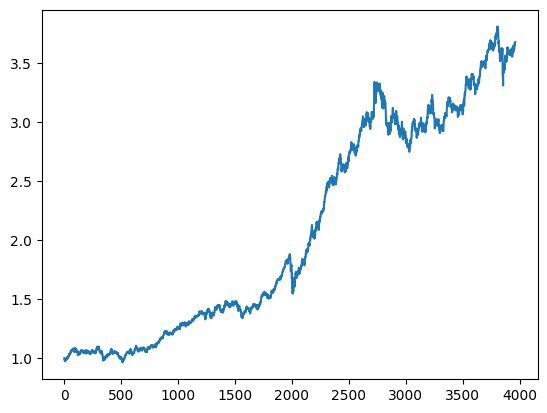

In [3]:
weight = [1/6,1/36,1/36,1/36,1/36,1/36,1/36,1/30,1/30,1/30,1/30,1/30,1/6,1/12,1/12,1/6]
ret = (data*weight).sum(axis =1 )
sharpe_ret = ret.mean()/ret.std()
print(sharpe_ret)
ret_cum = (ret+1).cumprod()
ret_cum.plot()

In [4]:
num_assets  = 6
threshold = 0.8
balance_time = 252

In [5]:
# prompt: weight a portfolio by MVO

def port(start):
  checked_data = data[start - balance_time:start]
  returns = checked_data.dropna()
  corr_matrix = returns.corr()
  mean_correlation = corr_matrix.mean()

  # Filter assets with mean correlation below the threshold
  eligible_assets = mean_correlation[mean_correlation < threshold]

  # Select up to `num_assets` assets with the lowest mean correlations
  selected_assets = eligible_assets.nsmallest(num_assets).index # Changed 'port' to 'selected_assets'
  mean_returns = returns[selected_assets].mean()
  cov_matrix = returns[selected_assets].cov()

  # Define the optimization problem
  # num_assets = len(returns.columns)
  # Set the risk aversion parameter (adjust as needed)
  risk_aversion = 1

  # Constraints: weights must sum to 1 and be non-negative
  constraints = ({'type': 'eq', 'fun': lambda x: np.sum(x) - 1})
  bounds = [(0, 1) for _ in range(num_assets)]  # Non-negative weights

  # Initial guess for weights (equal weights)
  initial_weights = np.array([1 / len(selected_assets)] * len(selected_assets)) # Changed 'port' to 'selected_assets'

  # Optimization function (to minimize negative Sharpe ratio)
  def negative_sharpe_ratio(weights):
      portfolio_return = np.sum(mean_returns * weights)
      portfolio_std_dev = np.sqrt(np.dot(weights.T, np.dot(cov_matrix, weights)))
      return -(portfolio_return / portfolio_std_dev)

  # Use minimize function from scipy.optimize
  from scipy.optimize import minimize
  optimized_results = minimize(negative_sharpe_ratio, initial_weights, method='SLSQP', bounds=bounds, constraints=constraints)

  # Optimal weights
  optimal_weights = optimized_results.x

  #portfolio creation
  # port = list(returns.columns) # Removed this line - kept 'selected_assets'
  end = start + balance_time
  forward_returns = data[selected_assets][start:end] # Changed 'port' to 'selected_assets'
  port_return = ((forward_returns*optimal_weights).sum(axis=1) +1).cumprod()[end-1] -1

  return selected_assets, port_return # Changed 'port' to 'selected_assets'

In [6]:
port(1000)

(Index(['UUP', 'IEF', 'GC=F', 'USDJPY=X', 'JPM', 'BTC-USD'], dtype='object', name='Ticker'),
 np.float64(0.27484837671783047))

In [7]:
portfolio_returns = []

i = balance_time
while i < data.index[-1]:
  portfolio, portfolio_return = port( i)
  portfolio_returns.append(portfolio_return)
  print (f'At {i} port is {portfolio} \n portfolio_return is {portfolio_return}')
  if i + 2*balance_time <= data.index[-1]:
    i += balance_time
  else:
    break


At 252 port is Index(['IEF', 'UUP', 'USDJPY=X', 'GC=F', 'KC=F', 'BTC-USD'], dtype='object', name='Ticker') 
 portfolio_return is 0.01589480451172398
At 504 port is Index(['IEF', 'GC=F', 'BTC-USD', 'ZW=F', 'USDJPY=X', 'SB=F'], dtype='object', name='Ticker') 
 portfolio_return is 0.14838867624562346
At 756 port is Index(['IEF', 'UUP', 'GC=F', 'USDJPY=X', 'SB=F', 'BTC-USD'], dtype='object', name='Ticker') 
 portfolio_return is 0.158020877519486
At 1008 port is Index(['UUP', 'GC=F', 'IEF', 'USDJPY=X', 'BTC-USD', 'JPM'], dtype='object', name='Ticker') 
 portfolio_return is 0.22094459975743574
At 1260 port is Index(['UUP', 'IEF', 'USDJPY=X', 'GC=F', 'SB=F', 'HG=F'], dtype='object', name='Ticker') 
 portfolio_return is -0.11561790395056493
At 1512 port is Index(['UUP', 'IEF', 'GC=F', 'BTC-USD', 'USDJPY=X', 'HG=F'], dtype='object', name='Ticker') 
 portfolio_return is 0.018829372756573592
At 1764 port is Index(['IEF', 'UUP', 'ZW=F', 'BTC-USD', 'GC=F', 'USDJPY=X'], dtype='object', name='Ticker'

0.8836219901902591


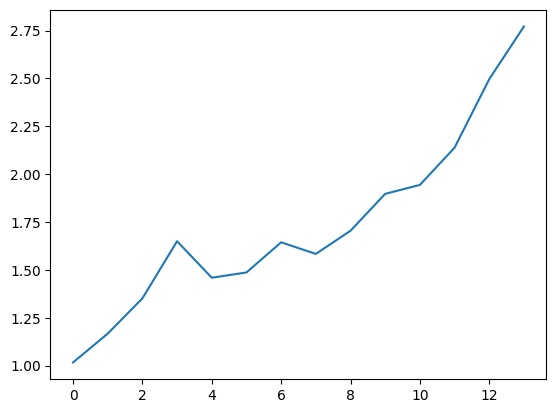

In [8]:
portfolio_returns = pd.Series(portfolio_returns)
port_cum = (1+portfolio_returns).cumprod()
port_sharpe = portfolio_returns.mean()/portfolio_returns.std()
print(port_sharpe)
plt.plot(port_cum)